# 04 · Fine-tuning
Full fine-tuning of BiomedCLIP and DINOv3 (encoder + new linear head) on the full training set.



## 0 · Setup + which runs

In [1]:
!pip install -q open_clip_torch pydicom "transformers>=4.56"

from google.colab import drive, userdata
drive.mount('/content/drive')

import os, json, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch

PROJECT = Path('/content/drive/MyDrive/345_term_project')
DATA, RESULTS, CKPT = PROJECT / 'data', PROJECT / 'results', PROJECT / 'checkpoints'
LOCAL = Path('/content/rsna')
for p in (RESULTS, CKPT, LOCAL):
    p.mkdir(parents=True, exist_ok=True)

os.environ['HF_TOKEN'] = userdata.get('HF_TOKEN')
DEVICE = 'cuda'
assert torch.cuda.is_available(), 'Switch to a GPU runtime (Runtime → Change runtime type).'

RUNS = [('BiomedCLIP', 'ft'), ('DINOv3', 'ft')]

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 79.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 107.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 4.0 MB/s eta 0:00:00
Mounted at /content/drive


## 1 · Training settings

In [2]:
ENCODER_LR   = 1e-5
HEAD_LR      = 1e-3
WEIGHT_DECAY = 0.01
BATCH        = 32
MAX_EPOCHS   = 10
PATIENCE     = 3
WARMUP_FRAC  = 0.05
SEED         = 0

## 2 · Splits + metrics

In [3]:
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             f1_score, confusion_matrix)

splits = pd.read_csv(DATA / 'splits.csv')
y = splits['label'].to_numpy()
TRAIN = np.flatnonzero(splits['split'] == 'train')
VAL   = np.flatnonzero(splits['split'] == 'val')
TEST  = np.flatnonzero(splits['split'] == 'test')
print(f'train {len(TRAIN)} | val {len(VAL)} | test {len(TEST)}')

def val_threshold(y_val, p_val):
    prec, rec, thr = precision_recall_curve(y_val, p_val)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    return thr[np.argmax(f1[:-1])]

def evaluate(p_val, p_test):
    t = val_threshold(y[VAL], p_val)
    yt, pred = y[TEST], (p_test >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(yt, pred, labels=[0, 1]).ravel()
    return {
        'val_pr_auc':  average_precision_score(y[VAL], p_val),
        'pr_auc':      average_precision_score(yt, p_test),
        'auroc':       roc_auc_score(yt, p_test),
        'f1':          f1_score(yt, pred, zero_division=0),
        'sensitivity': tp / (tp + fn),
        'specificity': tn / (tn + fp),
        'accuracy':    (tp + tn) / len(yt),
        'threshold':   t,
    }

train 18881 | val 3966 | test 3837


## 3 · Image cache (first run only)
DICOM → 224×224 grayscale.

In [4]:
CACHE = DATA / 'images_224.npy'

if not CACHE.exists():
    import pydicom
    from PIL import Image
    from multiprocessing import Pool
    if not (LOCAL / 'stage_2_train_images').exists():
        !unzip -q -o "{DATA / 'rsna-pneumonia-detection-challenge.zip'}" 'stage_2_train_images/*' -d "{LOCAL}"

    def load_224(image_id):
        ds = pydicom.dcmread(LOCAL / 'stage_2_train_images' / f'{image_id}.dcm')
        img = ds.pixel_array.astype(np.float32)
        if ds.get('PhotometricInterpretation') == 'MONOCHROME1':
            img = img.max() - img
        img = (255 * (img - img.min()) / max(img.max() - img.min(), 1)).astype(np.uint8)
        return np.asarray(Image.fromarray(img).resize((224, 224), Image.BICUBIC))

    with Pool(os.cpu_count()) as pool:
        IMAGES = np.stack(pool.map(load_224, splits['image_id'], chunksize=64))
    np.save(CACHE, IMAGES)
else:
    IMAGES = np.load(CACHE)
print(IMAGES.shape, IMAGES.dtype)

(26684, 224, 224) uint8


## 4 · Data loading
Each model's own normalization, taken from its preprocessing.

In [5]:
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import v2
from open_clip import create_model_from_pretrained
from transformers import AutoImageProcessor

BMC_NAME  = 'hf-hub:microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224'
DINO_NAME = 'facebook/dinov3-vitb16-pretrain-lvd1689m'

dino_processor = AutoImageProcessor.from_pretrained(DINO_NAME)
NORMALIZE = {
    'BiomedCLIP': create_model_from_pretrained(BMC_NAME)[1].transforms[-1],
    'DINOv3':     v2.Normalize(dino_processor.image_mean, dino_processor.image_std),
}

class XrayDataset(Dataset):
    def __init__(self, rows, backbone):
        self.rows, self.normalize = rows, NORMALIZE[backbone]
    def __len__(self):
        return len(self.rows)
    def __getitem__(self, i):
        r = self.rows[i]
        img = torch.from_numpy(IMAGES[r]).float().div(255).expand(3, -1, -1)
        return self.normalize(img), torch.tensor(y[r], dtype=torch.float32)

def make_loader(rows, backbone, train):
    return DataLoader(XrayDataset(rows, backbone), batch_size=BATCH, shuffle=train, drop_last=train,
                      num_workers=min(8, os.cpu_count()), pin_memory=True, persistent_workers=True)

preprocessor_config.json:   0%|          | 0.00/585 [00:00<?, ?B/s]

open_clip_config.json:   0%|          | 0.00/707 [00:00<?, ?B/s]

open_clip_pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  784MB            

open_clip_pytorch_model.bin: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

## 5 · Models

In [6]:
import torch.nn as nn
from transformers import AutoModel

class BiomedCLIPClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        clip, _ = create_model_from_pretrained(BMC_NAME)
        self.encoder = clip.visual
        self.head = nn.Linear(512, 1)

    def forward(self, x):
        return self.head(self.encoder(x)).squeeze(1)

class DINOv3Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(DINO_NAME)
        self.head = nn.Linear(2 * 768, 1)

    def forward(self, x):
        tokens = self.encoder(pixel_values=x).last_hidden_state
        cls, patches = tokens[:, 0], tokens[:, 5:]
        return self.head(torch.cat([cls, patches.mean(1)], dim=1)).squeeze(1)

MODELS = {'BiomedCLIP': BiomedCLIPClassifier, 'DINOv3': DINOv3Classifier}

def build_model(backbone, mode):
    model = MODELS[backbone]()
    if mode == 'lpft':
        model.head.load_state_dict(torch.load(RESULTS / f'probe_head_{backbone}.pt'))
    return model.to(DEVICE)

## 6 · Training loop

In [7]:
from tqdm.auto import tqdm

@torch.no_grad()
def predict(model, loader):
    model.eval()
    out = []
    for x, _ in loader:
        out.append(torch.sigmoid(model(x.to(DEVICE, non_blocking=True))).cpu())
    return torch.cat(out).numpy()

def train(backbone, mode):
    torch.manual_seed(SEED); np.random.seed(SEED)
    model = build_model(backbone, mode)
    train_loader = make_loader(TRAIN, backbone, train=True)
    val_loader   = make_loader(VAL, backbone, train=False)

    opt = torch.optim.AdamW([{'params': model.encoder.parameters(), 'lr': ENCODER_LR},
                             {'params': model.head.parameters(),    'lr': HEAD_LR}],
                            weight_decay=WEIGHT_DECAY)
    total = MAX_EPOCHS * len(train_loader)
    warmup = max(1, int(WARMUP_FRAC * total))
    sched = torch.optim.lr_scheduler.SequentialLR(opt, [
        torch.optim.lr_scheduler.LinearLR(opt, start_factor=1 / warmup, total_iters=warmup),
        torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=total - warmup),
    ], milestones=[warmup])
    loss_fn = nn.BCEWithLogitsLoss()

    best_score, best_state, best_epoch, waited, history = -1.0, None, 0, 0, []
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        t0, losses = time.time(), []
        for x, yb in tqdm(train_loader, desc=f'{backbone} {mode} epoch {epoch}', leave=False):
            loss = loss_fn(model(x.to(DEVICE, non_blocking=True)), yb.to(DEVICE))
            opt.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); sched.step()
            losses.append(loss.item())
        val_score = average_precision_score(y[VAL], predict(model, val_loader))
        history.append({'epoch': epoch, 'train_loss': np.mean(losses), 'val_pr_auc': val_score})
        print(f'epoch {epoch:2d}  train loss {np.mean(losses):.4f}  val PR-AUC {val_score:.4f}  ({time.time() - t0:.0f}s)')
        if val_score > best_score + 1e-4:
            best_score, best_epoch, waited = val_score, epoch, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            waited += 1
            if waited >= PATIENCE:
                print('early stop'); break
    model.load_state_dict(best_state)
    return model, best_epoch, pd.DataFrame(history)

## 7 · Run + evaluate

In [8]:
for backbone, mode in RUNS:
    tag = f'{backbone}_{mode}'
    if (RESULTS / f'finetune_{tag}.csv').exists():
        print('already done:', tag); continue

    model, best_epoch, hist = train(backbone, mode)
    p_val  = predict(model, make_loader(VAL, backbone, train=False))
    p_test = predict(model, make_loader(TEST, backbone, train=False))

    row = {'backbone': backbone, 'mode': mode, 'best_epoch': best_epoch, **evaluate(p_val, p_test)}
    pd.DataFrame([row]).to_csv(RESULTS / f'finetune_{tag}.csv', index=False)
    hist.to_csv(RESULTS / f'finetune_{tag}_history.csv', index=False)
    np.save(RESULTS / f'finetune_{tag}_val_preds.npy', p_val)
    np.save(RESULTS / f'finetune_{tag}_test_preds.npy', p_test)
    torch.save(model.state_dict(), CKPT / f'finetune_{tag}.pt')
    print(tag, {k: round(v, 3) for k, v in row.items() if isinstance(v, float)})
    del model; torch.cuda.empty_cache()

BiomedCLIP ft epoch 1:   0%|          | 0/590 [00:00<?, ?it/s]

epoch  1  train loss 0.4001  val PR-AUC 0.6414  (291s)


BiomedCLIP ft epoch 2:   0%|          | 0/590 [00:00<?, ?it/s]

epoch  2  train loss 0.3210  val PR-AUC 0.6512  (291s)


BiomedCLIP ft epoch 3:   0%|          | 0/590 [00:00<?, ?it/s]

epoch  3  train loss 0.2162  val PR-AUC 0.6393  (291s)


... (16 outputs left out)

DINOv3 ft epoch 5:   0%|          | 0/590 [00:00<?, ?it/s]

epoch  5  train loss 0.0596  val PR-AUC 0.5892  (335s)
early stop


Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x788e1a5e0e00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x788e1a5e0e00>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

DINOv3_ft {'val_pr_auc': np.float64(0.687), 'pr_auc': np.float64(0.693), 'auroc': np.float64(0.875), 'f1': 0.64, 'sensitivity': np.float64(0.658), 'specificity': np.float64(0.885), 'accuracy': np.float64(0.834)}


## 8 · Learning curves

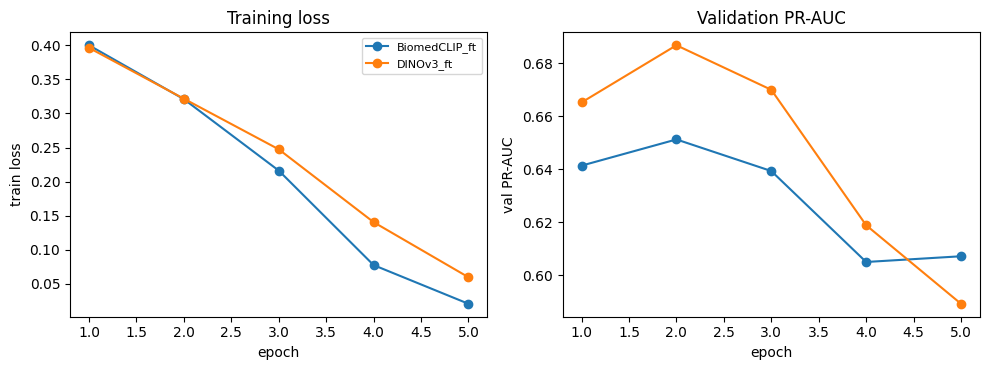

In [9]:
done = [f'{b}_{m}' for b, m in RUNS if (RESULTS / f'finetune_{b}_{m}_history.csv').exists()]
fig, (ax_loss, ax_val) = plt.subplots(1, 2, figsize=(10, 3.8))
for tag in done:
    h = pd.read_csv(RESULTS / f'finetune_{tag}_history.csv')
    ax_loss.plot(h.epoch, h.train_loss, 'o-', label=tag)
    ax_val.plot(h.epoch, h.val_pr_auc, 'o-', label=tag)
ax_loss.set(xlabel='epoch', ylabel='train loss', title='Training loss')
ax_val.set(xlabel='epoch', ylabel='val PR-AUC', title='Validation PR-AUC')
ax_loss.legend(fontsize=8)
plt.tight_layout(); plt.savefig(RESULTS / 'finetune_learning_curves.png', dpi=150)

## 9 · All results so far (test set)

,pr_auc,auroc,f1,sensitivity,specificity,accuracy
method,,,,,,
BiomedCLIP zero-shot (biomedclip),0.602,0.837,0.587,0.633,0.848,0.800
BiomedCLIP linear probe,0.659,0.853,0.610,0.674,0.846,0.807
DINOv3 linear probe,0.637,0.838,0.591,0.651,0.841,0.799
BiomedCLIP full fine-tuning,0.657,0.860,0.617,0.650,0.868,0.819
DINOv3 full fine-tuning,0.693,0.875,0.640,0.658,0.885,0.834


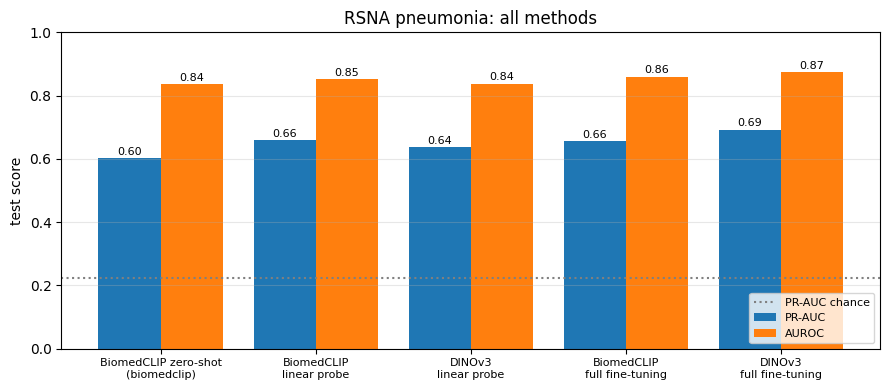

In [10]:
METRICS = ['pr_auc', 'auroc', 'f1', 'sensitivity', 'specificity', 'accuracy']
names = {'ft': 'full fine-tuning', 'lpft': 'LP-FT'}
ft = pd.concat([pd.read_csv(RESULTS / f'finetune_{t}.csv') for t in done])
ft['method'] = ft['backbone'] + ' ' + ft['mode'].map(names)
all_results = pd.concat([pd.read_csv(RESULTS / 'results_summary.csv', index_col='method')[METRICS],
                         ft.set_index('method')[METRICS]])
all_results.to_csv(RESULTS / 'all_results.csv')

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(all_results))
ax.bar(x - 0.2, all_results['pr_auc'], 0.4, label='PR-AUC')
ax.bar(x + 0.2, all_results['auroc'], 0.4, label='AUROC')
ax.axhline(y[TEST].mean(), color='gray', ls=':', label='PR-AUC chance')
for i, (pr, roc) in enumerate(zip(all_results['pr_auc'], all_results['auroc'])):
    ax.text(i - 0.2, pr + 0.01, f'{pr:.2f}', ha='center', fontsize=8)
    ax.text(i + 0.2, roc + 0.01, f'{roc:.2f}', ha='center', fontsize=8)
ax.set_xticks(x, [m.replace(' (', '\n(').replace(' linear', '\nlinear').replace(' full', '\nfull') for m in all_results.index], fontsize=8)
ax.set_ylim(0, 1); ax.set_ylabel('test score'); ax.set_title('RSNA pneumonia: all methods')
ax.legend(fontsize=8, loc='lower right'); ax.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.savefig(RESULTS / 'all_results_bar.png', dpi=200)
all_results.round(3)